In [1]:
import os, re, json, cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from multiprocessing import get_context

cv2.setNumThreads(1)

# BLOCO
- O notebook mede o **perfil sem rótulo** de um bloco sísmico real: o que o gerador sintético precisa cobrir para a rede ver no treino o mesmo mundo que vai ver na inferência
- Roda igual em qualquer bloco: só muda `BLOCK`. Um bloco é uma lista de pastas de tiles 128³ (`.dat` em `(inline, z, xline)`, já em $[0,1]$ pelo p01/p99 do bloco) com o `patch_metadata.json` delas
- Marlim: só as fatias de **dev** (1200, 1300) entram, todos os 1820 tiles, a regra do split; as de teste (1400, 2600) ficam intocadas até a validação final
- Iracema: `N_TILES` sorteados dos 38 528 tiles do bloco inteiro
- Nada aqui usa a interpretação do especialista

In [2]:
BLOCKS = {
    'marlim':  {'folders': ['../Blocks/Marlim/files/patches/1200/tiles', '../Blocks/Marlim/files/patches/1300/tiles'], 'metadata': None},
    'iracema': {'folders': ['../Blocks/Iracema/files/patches'], 'metadata': '../Blocks/Iracema/files/patch_metadata.json'},
}

BLOCK    = 'marlim'
N_TILES  = 2000                                   # TETO DE TILES SORTEADOS POR BLOCO (O DEV DO MARLIM TEM 1820: ENTRAM TODOS)
BAND     = 250                                    # ALTURA DAS FAIXAS DE z DO RELATÓRIO, EM AMOSTRAS
DATASETS = ['dataset_74', 'dataset_wu', 'dataset_74_wu', 'marlim_opt']
SEED     = 0
WORKERS  = 10
OUTPUT   = f'files/{BLOCK}'

os.makedirs(OUTPUT, exist_ok=True)
BLOCKS[BLOCK]

{'folders': ['../Blocks/Marlim/files/patches/1200/tiles',
  '../Blocks/Marlim/files/patches/1300/tiles'],
 'metadata': None}

# AMOSTRAS SEM RÓTULO
- `BlockSampler` lê o `patch_metadata.json` de cada pasta: os nomes dos tiles, a posição do núcleo de cada um no bloco (a mesma conta do `TileGrid` do `Blocks/Marlim/Analysis.ipynb`) e o **nível da água**, $-v_{min}/(v_{max}-v_{min})$, o zero do dado bruto na escala $[0,1]$ (0,50263 no Marlim, 0,49599 no Iracema)
- A posição em z vem do núcleo do tile; é ela que separa o tile em faixa de profundidade

In [3]:
# OS TILES 128³ DE UM BLOCO PELO patch_metadata.json DAS PASTAS: NOME, POSIÇÃO DO NÚCLEO E NÍVEL DA ÁGUA, SEM RÓTULO NENHUM
class BlockSampler:
    def __init__(self, folders, metadata=None, nTiles=None, seed=0):
        self.folders  = folders
        self.metadata = metadata
        self.nTiles   = nTiles
        self.seed     = seed

    def update(self):
        rows = [{'folder': folder, 'name': name, **self.getCore(info, name)} for folder in self.folders for info in [self.getInfo(folder)] for name in self.getNames(info)]
        self.table = pd.DataFrame(rows)
        self.water = float(np.mean([self.getWater(self.getInfo(folder)) for folder in self.folders]))

        if self.nTiles and len(self.table) > self.nTiles:
            self.table = self.table.sample(self.nTiles, random_state=self.seed).sort_index()

        return self.table

    def getInfo(self, folder):
        return json.load(open(self.metadata or f'{folder}/patch_metadata.json'))

    def getNames(self, info):
        return [f'patch_d{d:03d}_h{h:03d}_w{w:03d}.dat' for d, h, w in np.ndindex(*info['grid_shape'])]

    def getWater(self, info):
        return -info['vmin'] / (info['vmax'] - info['vmin'])

    # ORIGEM DO NÚCLEO DO TILE NO BLOCO: O ÚLTIMO DE CADA EIXO ENCOSTA NO FIM, COMO NO TileGrid
    def getCore(self, info, name):
        stride = info['patch_size'] - 2 * info['overlap_voxels']
        shape  = info.get('full_shape', info['original_shape'])
        index  = list(map(int, re.match(r'patch_d(\d+)_h(\d+)_w(\d+)\.dat', name).groups()))
        origin = [max(0, n - stride) if i == n // stride else i * stride for i, n in zip(index, shape)]
        return {'inline': origin[0], 'z': origin[1] + stride // 2, 'xline': origin[2]}

    def get(self, row):
        return np.fromfile(os.path.join(row['folder'], row['name']), np.float32).reshape((128, 128, 128))


sampler = BlockSampler(**BLOCKS[BLOCK], nTiles=N_TILES, seed=SEED)
tiles   = sampler.update()
print(f'{len(tiles)} tiles, água em {sampler.water:.5f}')
tiles.head()

1820 tiles, água em 0.50263


,folder,name,inline,z,xline
0,../Blocks/Marlim/files/patches/1200/tiles,patch_d000_h000_w000.dat,0,32,0
1,../Blocks/Marlim/files/patches/1200/tiles,patch_d000_h000_w001.dat,0,32,64
2,../Blocks/Marlim/files/patches/1200/tiles,patch_d000_h000_w002.dat,0,32,128
3,../Blocks/Marlim/files/patches/1200/tiles,patch_d000_h000_w003.dat,0,32,192
4,../Blocks/Marlim/files/patches/1200/tiles,patch_d000_h000_w004.dat,0,32,256


# RÉGUA
- `TileRuler` mede um tile pelas seções (z, lateral) inline e crossline em 32, 64 e 96, **na escala que a rede vê**: o mesmo código no tile real e no sintético
- Composição: água (|x − água| < 0,002) e seção viva (envelope RMS de σ 12 acima de 0,0552, o limiar de Otsu entre reflexão e zona morta do Marlim)
- Escala: período vertical pelo centróide do espectro em z e a largura relativa da banda
- Estrutura: coerência e mergulho dos refletores pelo tensor de estrutura, ponderados pela energia do gradiente
- Continuidade: fração da seção viva com semblance < 0,8 seguindo o mergulho em 5 traços (`disc5`) e em 17 (`disc17`), correlação lateral a 4 e 16 traços, e lineamentos de descontinuidade íngremes (40–80°) e deitados (0–20°)
- Textura e contraste: ruído fino (MAD da sub-banda HHH de Haar sobre o desvio do tile), curtose, tendência do contraste topo × base e saturação

In [4]:
def gauss(img, sigma):
    return cv2.GaussianBlur(img, (0, 0), sigmaX=sigma, sigmaY=sigma, borderType=cv2.BORDER_REFLECT)


# DESCRITORES DE UM TILE PELAS SEÇÕES (z, lateral): COMPOSIÇÃO, CONTRASTE, PERÍODO, MERGULHO, CONTINUIDADE E RUÍDO FINO
class TileRuler:
    ALIVE     = 0.0552                  # ENVELOPE RMS DO REFLETOR VIVO NA ESCALA [0, 1] (OTSU DO MARLIM)
    WATER_TOL = 0.002                   # |x - ÁGUA| QUE AINDA É ÁGUA
    DEAD_TOL  = 0.02                    # TRAÇO QUE NUNCA SAI DISSO É TRAÇO MORTO
    SLICES    = (32, 64, 96)            # SEÇÕES INLINE (EIXO 0) E CROSSLINE (EIXO 2) MEDIDAS
    STEEP     = (40, 50, 60, 70, 80)    # MERGULHOS DE LINEAMENTO TIPO FALHA, EM GRAUS
    FLAT      = (0, 10, 20)             # MERGULHOS DE LINEAMENTO AO LONGO DA CAMADA
    LINE      = 31                      # COMPRIMENTO DO NÚCLEO DE LINEAMENTO EM PX

    def __init__(self, water=None):
        self.water   = water
        self.kernels = {angle: self.getKernel(angle) for angle in self.STEEP + self.FLAT}

    def get(self, tile):
        tile  = np.asarray(tile, np.float32)
        table = pd.DataFrame([self.getSection(tile[i]) for i in self.SLICES] + [self.getSection(tile[:, :, j].T) for j in self.SLICES])
        return {**table.mean(numeric_only=True).to_dict(), **self.getVolume(tile)}

    # O QUE SÓ FAZ SENTIDO NO VOLUME: CONTRASTE, SATURAÇÃO, TRAÇOS MORTOS E O RUÍDO FINO DA SUB-BANDA HHH DE HAAR
    def getVolume(self, tile):
        center = self.water if self.water is not None else float(np.median(tile))
        a      = tile - center
        t      = tile[:tile.shape[0] // 2 * 2, :tile.shape[1] // 2 * 2, :tile.shape[2] // 2 * 2]
        hhh    = sum((-1) ** (i + j + k) * t[i::2, j::2, k::2] for i, j, k in np.ndindex(2, 2, 2)) / np.sqrt(8)
        rock   = np.abs(a[::2, ::2, ::2]) > self.WATER_TOL
        live   = np.abs(a) > self.WATER_TOL
        sd     = float(a[live].std()) if live.any() else 1e-6
        return {
            'sigma': float(tile.std()),
            'sat': float(((tile <= 0.002) | (tile >= 0.998)).mean()),
            'deadTraces': float((np.abs(a) < self.DEAD_TOL).all(axis=1).mean()),
            'fine': float(np.median(np.abs(hhh[rock])) / 0.6745 / (sd + 1e-9)) if rock.any() else np.nan
        }

    def getSection(self, section):
        a     = section.astype(np.float32) - (self.water if self.water is not None else float(np.median(section)))
        live  = np.sqrt(gauss(a * a, 12)) > self.ALIVE
        out   = {'water': float((np.abs(a) < self.WATER_TOL).mean()), 'live': float(live.mean())}

        if live.mean() < 0.05:
            return out

        zs      = a / (float(a[live].std()) + 1e-8)
        columns = live.mean(0) > 0.5
        return {**out, **self.getSpectrum(zs, columns), **self.getStructure(zs, live), **self.getContinuity(zs, live, columns), **self.getContrast(a, live)}

    # PERÍODO VERTICAL PELO CENTRÓIDE DO ESPECTRO EM z NAS COLUNAS VIVAS, E A LARGURA RELATIVA DA BANDA
    def getSpectrum(self, zs, columns):
        if columns.sum() < 8:
            return {}

        vert  = zs[:, columns] - zs[:, columns].mean(0)
        power = (np.abs(np.fft.rfft(vert, axis=0)) ** 2).mean(1)[1:]
        freqs = np.fft.rfftfreq(vert.shape[0])[1:]
        mean  = float((freqs * power).sum() / (power.sum() + 1e-12))
        width = float(np.sqrt(((freqs - mean) ** 2 * power).sum() / (power.sum() + 1e-12)))
        return {'period': 1.0 / (mean + 1e-12), 'bandwidth': width / (mean + 1e-12)}

    def getStructure(self, zs, live):
        Jzz, Jxx, Jzx = self.getTensor(zs)
        trace = (Jzz + Jxx) * live
        coh   = np.sqrt(np.maximum((Jzz - Jxx) ** 2 + 4 * Jzx ** 2, 0)) / (Jzz + Jxx + 1e-12)
        dip   = np.abs(np.degrees(0.5 * np.arctan2(2 * Jzx, Jzz - Jxx))).ravel()
        order = np.argsort(dip)
        cum   = np.cumsum(trace.ravel()[order]) / (trace.sum() + 1e-12)
        pick  = lambda q: float(dip[order][min(np.searchsorted(cum, q), cum.size - 1)])
        return {'coherence': float((coh * trace).sum() / (trace.sum() + 1e-12)), 'dipP50': pick(0.5), 'dipP90': pick(0.9)}

    def getContinuity(self, zs, live, columns):
        s5, s17 = self.getSemblance(zs, 2), self.getSemblance(zs, 8)
        disc    = np.clip(1 - s5, 0, 1).astype(np.float32)
        steep   = np.max([cv2.filter2D(disc, -1, self.kernels[a], borderType=cv2.BORDER_REFLECT) for a in self.STEEP], axis=0)
        flat    = np.max([cv2.filter2D(disc, -1, self.kernels[a], borderType=cv2.BORDER_REFLECT) for a in self.FLAT], axis=0)
        col     = zs[:, columns] / (zs[:, columns].std(0, keepdims=True) + 1e-8) if columns.sum() > 20 else None
        return {
            'disc5': float((s5 < 0.8)[live].mean()),
            'disc17': float((s17 < 0.8)[live].mean()),
            'steep90': float(np.percentile(steep[live], 90)),
            'flat90': float(np.percentile(flat[live], 90)),
            'lag4': float((col[:, :-4] * col[:, 4:]).mean()) if col is not None else np.nan,
            'lag16': float((col[:, :-16] * col[:, 16:]).mean()) if col is not None else np.nan
        }

    def getContrast(self, a, live):
        vals  = a[live]
        zs    = (vals - vals.mean()) / (vals.std() + 1e-8)
        third = a.shape[0] // 3
        top   = a[:third][live[:third]]
        base  = a[-third:][live[-third:]]
        trend = float(np.log((top.std() + 1e-6) / (base.std() + 1e-6))) if top.size > 100 and base.size > 100 else np.nan
        return {'kurt': float((zs ** 4).mean()), 'trend': trend, 'sigmaLive': float(vals.std())}

    def getTensor(self, zs):
        smooth = gauss(zs, 1.0)
        gz, gx = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3), cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)
        return gauss(gz * gz, 4.0), gauss(gx * gx, 4.0), gauss(gz * gx, 4.0)

    # NÚCLEO DE LINHA DE LINE px NO MERGULHO DADO (0 = HORIZONTAL), NORMALIZADO PARA MÉDIA
    def getKernel(self, angle):
        size   = self.LINE + (self.LINE + 1) % 2
        kernel = np.zeros((size, size), np.float32)
        c, r   = size // 2, self.LINE / 2
        dz, dx = np.sin(np.radians(angle)), np.cos(np.radians(angle))
        cv2.line(kernel, (int(round(c - r * dx)), int(round(c - r * dz))), (int(round(c + r * dx)), int(round(c + r * dz))), 1.0, 1)
        return kernel / kernel.sum()

    # SEMBLANCE DE 2·half+1 TRAÇOS SEGUINDO O MERGULHO LOCAL, NUMA JANELA DE 9 AMOSTRAS (A MESMA DO Regions/Marlim)
    def getSemblance(self, section, half, win=4):
        Jzz, Jxx, Jzx = self.getTensor(section)
        dip    = np.clip(-np.tan(0.5 * np.arctan2(2 * Jzx, Jzz - Jxx)), -3, 3)
        zz, xx = np.mgrid[:section.shape[0], :section.shape[1]].astype(np.float32)
        traces = [cv2.remap(section, xx + k, zz + dip * k, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT) for k in range(-half, half + 1)]
        window = np.ones((2 * win + 1, 1), np.float32)
        num    = cv2.filter2D(sum(traces) ** 2, -1, window, borderType=cv2.BORDER_REFLECT)
        den    = cv2.filter2D(sum(t * t for t in traces) * len(traces), -1, window, borderType=cv2.BORDER_REFLECT)
        return num / (den + 1e-12)


ruler = TileRuler(sampler.water)
row   = tiles.iloc[int(((tiles.z - tiles.z.median()) ** 2 + (tiles.xline - tiles.xline.median()) ** 2).argmin())]
pd.Series(ruler.get(sampler.get(row))).round(4)

water          0.0089
live           1.0000
period        19.1635
bandwidth      0.5223
coherence      0.8594
dipP50        19.5297
dipP90        41.2926
disc5          0.0826
disc17         0.3848
steep90        0.2058
flat90         0.1555
lag4           0.7479
lag16          0.0819
kurt           3.1523
trend         -0.4700
sigmaLive      0.2258
sigma          0.2261
sat            0.0780
deadTraces     0.0000
fine           0.0091
dtype: float64

# PERFIL DO BLOCO
- A régua passa em todos os tiles sorteados (processos por `fork`, por isso o `cv2.setNumThreads(1)` da primeira célula) e o perfil fica em `files/<bloco>/profile.pkl`
- Classe de cada tile, sem rótulo: **água** (> metade das seções é água), **morto** (< 10% vivo: zona morta, abaixo do alcance do dado), **refletivo** (> 90% vivo) e **misto**
- A composição é o que a rede vê na inferência: tudo o que não é refletivo nunca aparece num dataset sintético comum

In [5]:
def measure(task):
    return TileRuler(sampler.water).get(sampler.get(task))


if os.path.exists(f'{OUTPUT}/profile.pkl'):
    profile = pd.read_pickle(f'{OUTPUT}/profile.pkl')
else:
    with get_context('fork').Pool(WORKERS) as pool:
        rows = pool.map(measure, [row for _, row in tiles.iterrows()], chunksize=4)

    profile = pd.concat([tiles.reset_index(drop=True), pd.DataFrame(rows)], axis=1)
    profile.to_pickle(f'{OUTPUT}/profile.pkl')

profile['classe'] = np.select([profile.water > 0.5, profile.live < 0.1, profile.live > 0.9], ['água', 'morto', 'refletivo'], 'misto')
profile['faixa']  = (profile.z // BAND * BAND).astype(int)
pd.crosstab(profile.faixa, profile.classe, margins=True)

classe,misto,morto,refletivo,água,All
faixa,,,,,
0,15,0,13,252,280
250,33,0,201,46,280
500,114,0,166,0,280
750,54,14,212,0,280
1000,118,59,103,0,280
1250,19,191,0,0,210
1500,0,210,0,0,210
All,353,474,695,298,1820


In [6]:
FEATURES = ['period', 'bandwidth', 'sigmaLive', 'sat', 'fine', 'coherence', 'dipP90', 'disc5', 'disc17', 'lag4', 'lag16', 'steep90', 'flat90', 'kurt', 'trend']
live     = profile[profile.live > 0.5]
quantile = lambda s: f'{s.quantile(0.1):.3g} / {s.median():.3g} / {s.quantile(0.9):.3g}'

live.groupby('faixa')[FEATURES].agg(quantile).T

faixa,0,250,500,750,1000
period,4.07 / 4.16 / 4.25,4.17 / 4.65 / 7.07,6.08 / 10 / 16.6,15.3 / 18.6 / 22,16.1 / 20.3 / 28
bandwidth,0.332 / 0.353 / 0.395,0.309 / 0.364 / 0.421,0.372 / 0.432 / 0.503,0.458 / 0.551 / 0.663,0.484 / 0.631 / 0.742
sigmaLive,0.172 / 0.201 / 0.233,0.131 / 0.185 / 0.279,0.0927 / 0.136 / 0.24,0.119 / 0.226 / 0.31,0.107 / 0.204 / 0.327
sat,0.0351 / 0.0445 / 0.084,0.00649 / 0.0353 / 0.16,0 / 0.00257 / 0.101,0.000912 / 0.0691 / 0.21,0 / 0.038 / 0.251
fine,0.016 / 0.0173 / 0.0249,0.0124 / 0.0194 / 0.0267,0.00919 / 0.012 / 0.0174,0.00463 / 0.00686 / 0.0105,0.00347 / 0.00544 / 0.00822
coherence,0.97 / 0.977 / 0.982,0.974 / 0.984 / 0.994,0.916 / 0.972 / 0.985,0.883 / 0.924 / 0.963,0.877 / 0.946 / 0.975
dipP90,2.84 / 3.57 / 5,4.84 / 7.16 / 9.74,6.46 / 10.3 / 25.1,13.8 / 21.3 / 36.4,14.7 / 21.6 / 31.6
disc5,0.00536 / 0.00767 / 0.0187,0.00081 / 0.00733 / 0.031,0.00557 / 0.0167 / 0.0355,0.00732 / 0.0298 / 0.0698,0.00324 / 0.0199 / 0.0536
disc17,0.111 / 0.134 / 0.302,0.0408 / 0.121 / 0.272,0.0724 / 0.16 / 0.281,0.0717 / 0.192 / 0.365,0.0379 / 0.129 / 0.337
lag4,0.81 / 0.865 / 0.894,0.673 / 0.813 / 0.913,0.789 / 0.881 / 0.946,0.799 / 0.904 / 0.952,0.824 / 0.913 / 0.976


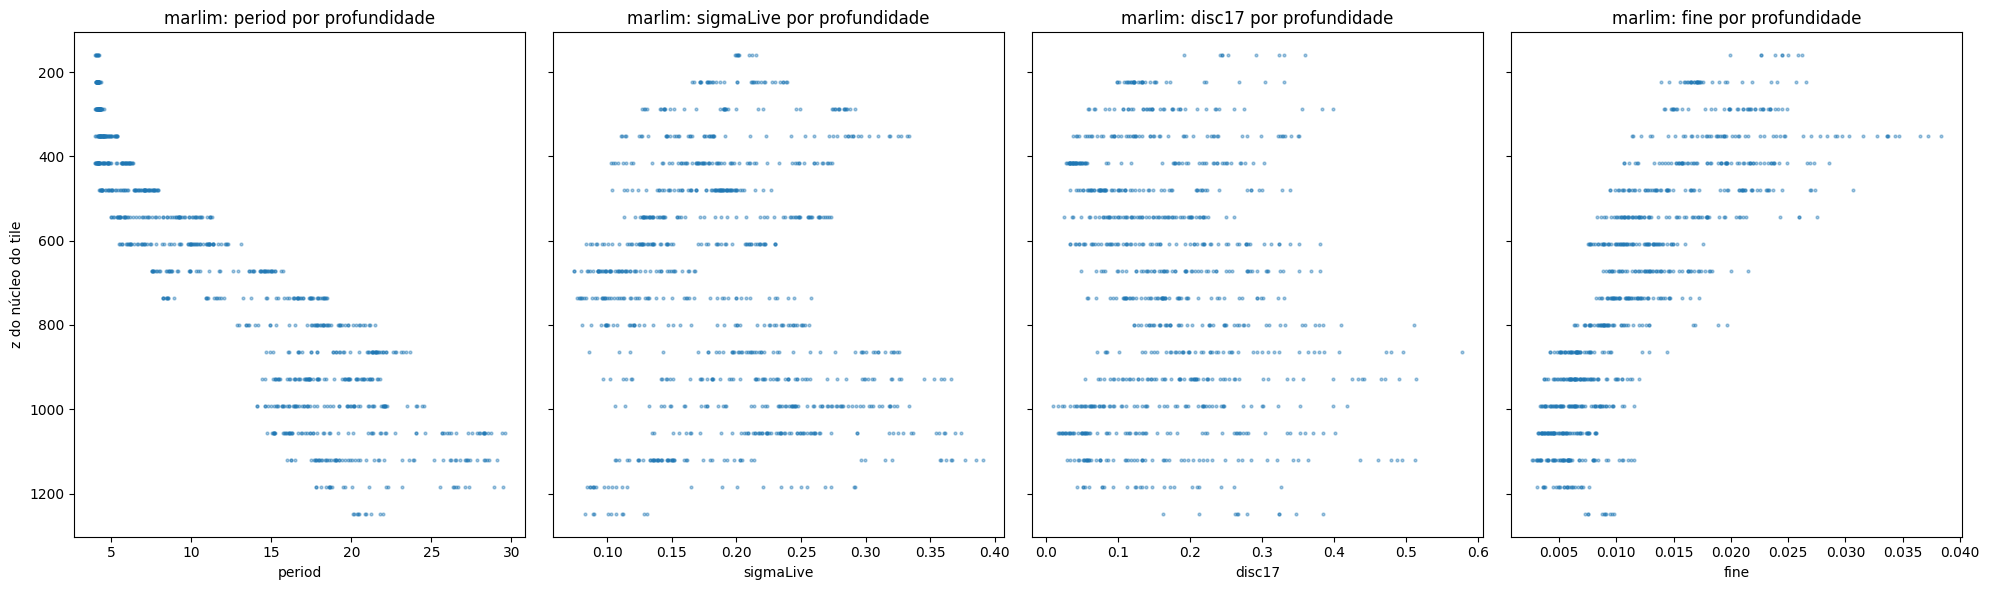

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 6), sharey=True)
for ax, name in zip(axes, ['period', 'sigmaLive', 'disc17', 'fine']):
    ax.scatter(live[name], live.z, s=4, alpha=0.4)
    ax.set_xlabel(name)
    ax.set_title(f'{BLOCK}: {name} por profundidade')
axes[0].set_ylabel('z do núcleo do tile')
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig(f'{OUTPUT}/profile.png', dpi=80)
plt.show()

# LACUNA DOS DATASETS
- Os datasets sintéticos passam pela mesma régua, já na escala do treino (os `images/` do `Format`; o `dataset_74_wu` não tem `images/` próprios e é lido pelos caminhos do `DataBase.csv`)
- **Cobertura** de um descritor: fração dos tiles reais vivos dentro do p2,5–p97,5 do sintético. Um descritor com cobertura baixa é uma parte do bloco que a rede nunca viu no treino
- É o diagnóstico que orienta as mudanças do gerador; se ele serve como objetivo da calibração é a meta-validação que diz (`files/experiments/meta.py`)

In [8]:
def measureSynthetic(path):
    return TileRuler().get(np.load(path))


synthetic = {}
for name in DATASETS:
    paths = pd.read_csv(f'../Dataset/{name}/DataBase.csv').img_path.tolist()
    with get_context('fork').Pool(WORKERS) as pool:
        synthetic[name] = pd.DataFrame(pool.map(measureSynthetic, paths, chunksize=4))

pd.DataFrame({name: table[FEATURES].median() for name, table in synthetic.items()} | {f'{BLOCK} (vivos)': live[FEATURES].median()}).round(3)

,dataset_74,dataset_wu,dataset_74_wu,marlim_opt,marlim (vivos)
period,9.443,7.392,8.257,9.930,12.906
bandwidth,0.537,0.397,0.414,0.466,0.449
sigmaLive,0.125,0.099,0.106,0.165,0.187
sat,0.000,0.000,0.000,0.007,0.036
fine,0.047,0.052,0.048,0.024,0.011
coherence,0.916,0.930,0.926,0.945,0.968
dipP90,24.943,24.259,24.641,18.448,12.641
disc5,0.127,0.099,0.106,0.112,0.016
disc17,0.395,0.456,0.428,0.338,0.154
lag4,0.631,0.513,0.558,0.769,0.880


In [9]:
coverage = {name: {c: float(((live[c] >= table[c].quantile(0.025)) & (live[c] <= table[c].quantile(0.975))).mean()) for c in FEATURES} for name, table in synthetic.items()}
pd.DataFrame(coverage).round(2)

,dataset_74,dataset_wu,dataset_74_wu,marlim_opt
period,0.13,0.16,0.18,0.81
bandwidth,0.84,0.58,0.92,0.92
sigmaLive,0.28,0.17,0.32,0.85
sat,0.00,0.00,0.00,0.82
fine,0.52,0.88,0.77,0.80
coherence,0.51,0.58,0.56,0.95
dipP90,0.51,0.60,0.58,0.88
disc5,0.23,0.30,0.28,0.86
disc17,0.49,0.50,0.48,0.89
lag4,0.34,0.31,0.32,0.93


# RESPOSTA DO GERADOR
- A parte medida da calibração (M4) traduz o período medido no bloco em `waveletFreq`; para isso mede-se, **com a mesma régua**, o período que o gerador entrega em cada frequência nominal do Ricker
- `FREQS` fixas, `N_MAP` tiles por frequência no modo `fast`, base sem água nem zona morta (só o refletor vivo entra no período); o mapa é do gerador, não do bloco, e fica em `files/period_map.csv`
- O período cai como ≈ 1/f, puxado para cima nos períodos curtos pelo ruído; abaixo de ~4,5 px a régua satura (o centróide de um espectro branco dá ~4 px)

In [10]:
import sys
sys.path.append('..')
from Synthetic.index import SyntheticGenerator

FREQS    = [16, 20, 26, 33, 40, 50, 65, 80, 100, 130, 160, 208, 260, 320]
N_MAP    = 8
MAP_BASE = {'waveletLog': True, 'noiseLevel': (0.0, 0.15), 'faultCount': (1, 5), 'bodyCount': (0, 3), 'gainField': 0.4, 'waveletPhase': (-90.0, 90.0), 'lensSigma': (8, 50), 'lensCut': (0.0, 0.5), 'bodyLayers': 0.5, 'fast': True}


def getMapTile(freq, seed):
    generator = SyntheticGenerator(seed=seed)
    generator.set({**MAP_BASE, 'waveletFreq': (freq, freq)})
    image = np.transpose(generator.get()[0], (0, 2, 1))
    return (image - image.min()) / (image.max() - image.min())


if os.path.exists('files/period_map.csv'):
    periodMap = pd.read_csv('files/period_map.csv')
else:
    periodMap = pd.DataFrame([{'f': f, 'semente': s, 'period': TileRuler().get(getMapTile(f, 5000 + 100 * f + s)).get('period', np.nan)} for f in FREQS for s in range(N_MAP)])
    periodMap.to_csv('files/period_map.csv', index=False)

periodMap.groupby('f').period.describe(percentiles=[0.1, 0.5, 0.9])[['10%', '50%', '90%']].round(1).T

f,16,20,26,33,40,50,65,80,100,130,160,208,260,320
10%,37.8,31.1,25.1,20.0,17.2,14.3,11.8,9.8,8.4,6.6,5.8,4.8,4.1,3.8
50%,39.7,35.0,26.7,22.6,18.7,15.2,12.1,10.8,8.8,7.1,6.2,5.0,4.4,4.1
90%,49.9,37.6,30.3,24.4,20.1,16.9,13.3,11.5,9.6,7.2,7.1,5.6,4.8,4.9
